In [1]:
import numpy as np
import pandas as pd

# =========================
# 1) VERİ YÜKLEME
# =========================

columns = ["UnitNumber", "Time", "OpSet1", "OpSet2"] + [f"Sensor{i}" for i in range(1, 22)]

train_path = "data/train_FD001.txt"
test_path  = "data/test_FD001.txt"

train_df_orig = pd.read_csv(train_path, sep=r"\s+", header=None, names=columns)
test_df_orig  = pd.read_csv(test_path,  sep=r"\s+", header=None, names=columns)

train_df = train_df_orig.copy()
test_df  = test_df_orig.copy()

print("Train shape:", train_df.shape)
print("Test shape :", test_df.shape)
train_df.head()

Train shape: (20631, 25)
Test shape : (13096, 25)


,UnitNumber,Time,OpSet1,OpSet2,Sensor1,Sensor2,Sensor3,Sensor4,Sensor5,Sensor6,...,Sensor12,Sensor13,Sensor14,Sensor15,Sensor16,Sensor17,Sensor18,Sensor19,Sensor20,Sensor21
1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [2]:
from sklearn.preprocessing import StandardScaler

# =========================
# 2) PREPROCESSING
# =========================

sensor_cols = [c for c in train_df.columns if c.startswith("Sensor")]

train_df[sensor_cols] = train_df[sensor_cols].replace([np.inf, -np.inf], np.nan)
test_df[sensor_cols]  = test_df[sensor_cols].replace([np.inf, -np.inf], np.nan)

before_tr, before_te = train_df.shape[0], test_df.shape[0]
train_df = train_df.dropna(subset=sensor_cols).reset_index(drop=True)
test_df  = test_df.dropna(subset=sensor_cols).reset_index(drop=True)

print(f"Drop NA (train): {before_tr} -> {train_df.shape[0]}")
print(f"Drop NA (test) : {before_te} -> {test_df.shape[0]}")

# Leakage-safe scaler: sadece train üzerinde fit
x_scaler = StandardScaler()
X_train_scaled = x_scaler.fit_transform(train_df[sensor_cols].values.astype("float32"))
X_test_scaled  = x_scaler.transform(test_df[sensor_cols].values.astype("float32"))

print("X_train_scaled:", X_train_scaled.shape)
print("X_test_scaled :", X_test_scaled.shape)

Drop NA (train): 20631 -> 20631
Drop NA (test) : 13096 -> 13096
X_train_scaled: (20631, 21)
X_test_scaled : (13096, 21)


In [3]:
import tensorflow as tf
from tensorflow.keras import layers, Model

# =========================
# 3) AUTOENCODER
# =========================

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

input_dim = X_train_scaled.shape[1]
encoding_dim = 21  # revizyon kararı

inputs = layers.Input(shape=(input_dim,), name="inp")
x = layers.Dense(input_dim * 2, activation="relu", name="enc_dense_1")(inputs)
x = layers.Dense(input_dim, activation="relu", name="enc_dense_2")(x)
latent = layers.Dense(encoding_dim, activation="linear", name="latent")(x)

x = layers.Dense(input_dim, activation="relu", name="dec_dense_1")(latent)
x = layers.Dense(input_dim * 2, activation="relu", name="dec_dense_2")(x)
outputs = layers.Dense(input_dim, activation="linear", name="out")(x)

autoencoder = Model(inputs, outputs, name="ae_recon")
autoencoder.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")

es = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = autoencoder.fit(
    X_train_scaled, X_train_scaled,
    epochs=100,
    batch_size=256,
    validation_split=0.2,
    callbacks=[es],
    verbose=0
)

print("Input dimension :", input_dim)
print("Latent dimension:", encoding_dim)
print("Best val_loss   :", np.min(history.history["val_loss"]))

Input dimension : 21
Latent dimension: 21
Best val_loss   : 0.0008785153622739017


In [4]:
# =========================
# 4) LATENT SPACE OLUŞTURMA
# =========================

encoder = Model(inputs=autoencoder.input, outputs=autoencoder.get_layer("latent").output)

z_train_raw = encoder.predict(X_train_scaled, verbose=0)
z_test_raw  = encoder.predict(X_test_scaled,  verbose=0)

# Latent space için ayrı scaler: sadece train'de fit
z_scaler = StandardScaler()
z_train = z_scaler.fit_transform(z_train_raw)
z_test  = z_scaler.transform(z_test_raw)

print("Shapes -> z_train:", z_train.shape, "| z_test:", z_test.shape)

Shapes -> z_train: (20631, 21) | z_test: (13096, 21)


In [5]:
# =========================
# 5) RECONSTRUCTION ERROR
# =========================

X_train_recon = autoencoder.predict(X_train_scaled, verbose=0)
X_test_recon  = autoencoder.predict(X_test_scaled,  verbose=0)

re_train = np.mean((X_train_scaled - X_train_recon) ** 2, axis=1)
re_test  = np.mean((X_test_scaled  - X_test_recon) ** 2, axis=1)

print("RE train -> mean:", re_train.mean(), "std:", re_train.std())
print("RE test  -> mean:", re_test.mean(),  "std:", re_test.std())

RE train -> mean: 0.0008963237 std: 0.0031007312
RE test  -> mean: 0.0010407473 std: 0.004024815


In [6]:
# =========================
# 6) PSEUDO-LABEL + ROBUSTNESS
# =========================

mu, sigma = re_train.mean(), re_train.std()
p90, p92, p95 = np.percentile(re_train, [90, 92, 95])

threshold_candidates = {
    "mu+1.8s": mu + 1.8 * sigma,
    "mu+2.0s": mu + 2.0 * sigma,
    "mu+2.5s": mu + 2.5 * sigma,
    "p90": p90,
    "p92": p92,
    "p95": p95,
    "combined": max(mu + 2.5 * sigma, p95)
}

robustness_rows = []
for name, thr in threshold_candidates.items():
    y_tr_tmp = (re_train > thr).astype(int)
    y_te_tmp = (re_test  > thr).astype(int)
    robustness_rows.append([
        name,
        thr,
        y_tr_tmp.mean() * 100,
        y_te_tmp.mean() * 100
    ])

df_thresholds = pd.DataFrame(
    robustness_rows,
    columns=["Threshold Strategy", "Threshold Value", "Train Anomaly Ratio (%)", "Test Anomaly Ratio (%)"]
)

print("== Eşik adayları ==")
display(df_thresholds)

# Seçilen threshold
SELECTED_THRESHOLD = "mu+2.0s"   # burada istersen combined'e çekebilirsin
threshold = threshold_candidates[SELECTED_THRESHOLD]

y_train = (re_train > threshold).astype(int)
y_test  = (re_test  > threshold).astype(int)

print(f"Seçilen eşik -> {SELECTED_THRESHOLD}: {threshold:.6f}")
print(f"Pseudo-label oranı (train): {y_train.mean()*100:.2f}% | (test): {y_test.mean()*100:.2f}%")

== Eşik adayları ==


,Threshold Strategy,Threshold Value,Train Anomaly Ratio (%),Test Anomaly Ratio (%)
0,mu+1.8s,0.006478,1.817653,2.718387
1,mu+2.0s,0.007098,1.725559,2.588577
2,mu+2.5s,0.008648,1.478358,2.328955
3,p90,0.001369,9.999515,9.094380
4,p92,0.001562,8.002520,7.513745
5,p95,0.002080,5.002181,5.207697
6,combined,0.008648,1.478358,2.328955


Seçilen eşik -> mu+2.0s: 0.007098
Pseudo-label oranı (train): 1.73% | (test): 2.59%


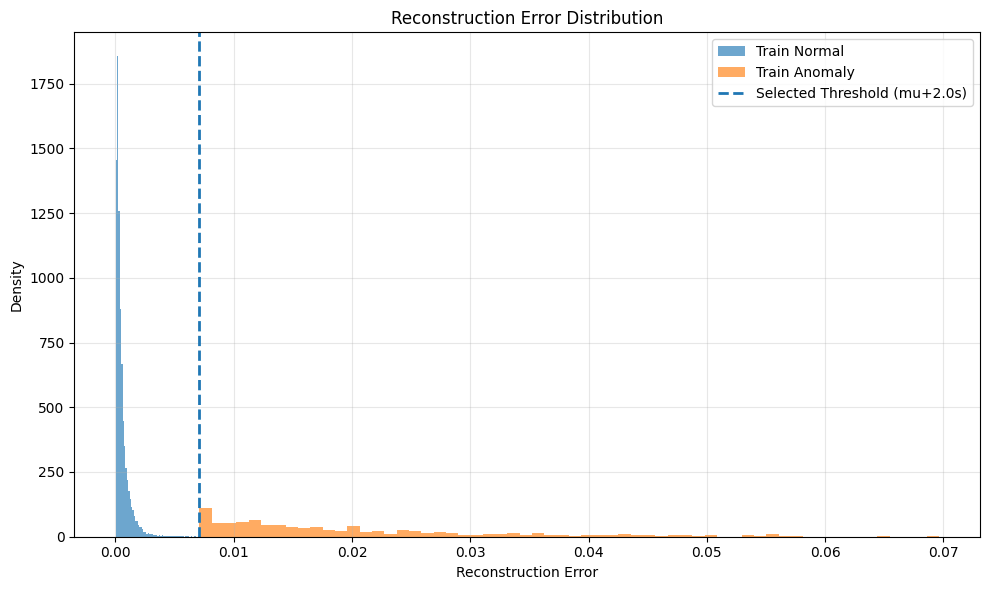

Saved: Figure_Reconstruction_Error_Histogram.png
Full path: /Users/emredelibas/Documents/Akademik/Python/ServetMakale/Figure_Reconstruction_Error_Histogram.png


In [7]:
import matplotlib.pyplot as plt
import os

# =========================
# EK CELL B) RECONSTRUCTION ERROR HISTOGRAM
# Makaledeki yeri: Pseudo-labeling bölümü veya Results başı
# Export: 600 dpi PNG
# =========================

plt.figure(figsize=(10, 6))

# Train normal
plt.hist(
    re_train[y_train == 0],
    bins=60,
    alpha=0.65,
    label="Train Normal",
    density=True
)

# Train anomaly
plt.hist(
    re_train[y_train == 1],
    bins=60,
    alpha=0.65,
    label="Train Anomaly",
    density=True
)

# Threshold çizgisi
plt.axvline(
    threshold,
    linestyle="--",
    linewidth=2,
    label=f"Selected Threshold ({SELECTED_THRESHOLD})"
)

plt.xlabel("Reconstruction Error")
plt.ylabel("Density")
plt.title("Reconstruction Error Distribution")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

hist_path = "Figure_Reconstruction_Error_Histogram.png"
plt.savefig(hist_path, dpi=600, bbox_inches="tight")
plt.show()

print(f"Saved: {hist_path}")
print("Full path:", os.path.abspath(hist_path))

In [8]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score
from sklearn.cluster import DBSCAN
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM

# =========================
# 7) YARDIMCI FONKSİYONLAR
# =========================

def safe_auc(y_true, scores):
    try:
        if scores is None:
            return np.nan
        if len(np.unique(y_true)) < 2:
            return np.nan
        return roc_auc_score(y_true, scores)
    except Exception:
        return np.nan

def metric_pack(y_true, y_pred, scores=None):
    return {
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "Macro-F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "ROC-AUC": safe_auc(y_true, scores if scores is not None else y_pred)
    }

def dbscan_predict_like_train_test(X_train, X_test, eps, min_samples):
    # DBSCAN için gerçek predict yok; makaledeki mevcut mantığa sadık kalmak için test üzerinde noise tespiti
    db = DBSCAN(eps=eps, min_samples=min_samples)
    test_labels = db.fit_predict(X_test)
    y_pred = (test_labels == -1).astype(int)
    scores = y_pred.astype(float)
    return y_pred, scores

def if_predict(X_train, X_test, n_estimators, contamination):
    model = IsolationForest(
        n_estimators=n_estimators,
        contamination=contamination,
        random_state=42
    )
    model.fit(X_train)
    pred = model.predict(X_test)
    y_pred = (pred == -1).astype(int)
    scores = -model.decision_function(X_test)
    return y_pred, scores

def lof_predict(X_train, X_test, n_neighbors):
    model = LocalOutlierFactor(
        n_neighbors=n_neighbors,
        novelty=True
    )
    model.fit(X_train)
    pred = model.predict(X_test)
    y_pred = (pred == -1).astype(int)
    scores = -model.decision_function(X_test)
    return y_pred, scores

def ocsvm_predict(X_train, X_test, nu, gamma):
    model = OneClassSVM(nu=nu, gamma=gamma)
    model.fit(X_train)
    pred = model.predict(X_test)
    y_pred = (pred == -1).astype(int)
    scores = -model.decision_function(X_test)
    return y_pred, scores

def knn_predict(X_train, X_test, k, percentile):
    nn = NearestNeighbors(n_neighbors=k)
    nn.fit(X_train)

    tr_dist, _ = nn.kneighbors(X_train)
    tr_scores = tr_dist[:, -1]
    thr = np.percentile(tr_scores, percentile)

    te_dist, _ = nn.kneighbors(X_test)
    te_scores = te_dist[:, -1]
    y_pred = (te_scores > thr).astype(int)
    return y_pred, te_scores, thr

In [9]:
# =========================
# 8) HYBRID ANOMALY DETECTION
# =========================

BEST_XSCALED = dict(
    dbscan_eps=4.70, dbscan_min_samples=500,
    if_estimators=200, if_contamination=max(y_train.mean(), 0.01),
    lof_neighbors=500,
    ocsvm_nu=max(y_train.mean(), 0.01), ocsvm_gamma=0.0001,
    knn_k=300, knn_percentile=97
)

BEST_ZLATENT = dict(
    dbscan_eps=9.70, dbscan_min_samples=500,
    if_estimators=200, if_contamination=max(y_train.mean(), 0.01),
    lof_neighbors=500,
    ocsvm_nu=max(y_train.mean(), 0.01), ocsvm_gamma=0.0001,
    knn_k=300, knn_percentile=97
)

def run_all_models(X_train, X_test, y_true, params, tag):
    rows = []

    # DBSCAN
    y_pred, scores = dbscan_predict_like_train_test(
        X_train, X_test,
        params["dbscan_eps"],
        params["dbscan_min_samples"]
    )
    m = metric_pack(y_true, y_pred, scores)
    rows.append([tag, "DBSCAN", *m.values()])

    # IF
    y_pred, scores = if_predict(
        X_train, X_test,
        params["if_estimators"],
        params["if_contamination"]
    )
    m = metric_pack(y_true, y_pred, scores)
    rows.append([tag, "IsolationForest", *m.values()])

    # LOF
    y_pred, scores = lof_predict(
        X_train, X_test,
        params["lof_neighbors"]
    )
    m = metric_pack(y_true, y_pred, scores)
    rows.append([tag, "LOF", *m.values()])

    # OCSVM
    y_pred, scores = ocsvm_predict(
        X_train, X_test,
        params["ocsvm_nu"],
        params["ocsvm_gamma"]
    )
    m = metric_pack(y_true, y_pred, scores)
    rows.append([tag, "OCSVM", *m.values()])

    # kNN
    y_pred, scores, thr = knn_predict(
        X_train, X_test,
        params["knn_k"],
        params["knn_percentile"]
    )
    m = metric_pack(y_true, y_pred, scores)
    rows.append([tag, f"kNN (k={params['knn_k']}, p{params['knn_percentile']})", *m.values()])

    return pd.DataFrame(
        rows,
        columns=["Space", "Model", "Precision", "Recall", "F1", "Macro-F1", "ROC-AUC"]
    )

df_raw_opt    = run_all_models(X_train_scaled, X_test_scaled, y_test, BEST_XSCALED, "Raw")
df_latent_opt = run_all_models(z_train, z_test, y_test, BEST_ZLATENT, "Latent")

df_compare = pd.concat([df_raw_opt, df_latent_opt], ignore_index=True)
display(df_compare)

,Space,Model,Precision,Recall,F1,Macro-F1,ROC-AUC
0,Raw,DBSCAN,0.834184,0.964602,0.894665,0.945820,0.979753
1,Raw,IsolationForest,0.937500,0.044248,0.084507,0.535964,0.981174
2,Raw,LOF,0.828496,0.926254,0.874652,0.935559,0.993943
3,Raw,OCSVM,0.570552,0.274336,0.370518,0.679109,0.943722
4,Raw,"kNN (k=300, p97)",0.778325,0.466077,0.583026,0.787107,0.990665
5,Latent,DBSCAN,0.834184,0.964602,0.894665,0.945820,0.979753
6,Latent,IsolationForest,0.852941,0.769912,0.809302,0.902244,0.991383
7,Latent,LOF,0.823678,0.964602,0.888587,0.942683,0.993816
8,Latent,OCSVM,0.585366,0.353982,0.441176,0.714662,0.959624
9,Latent,"kNN (k=300, p97)",0.763158,0.513274,0.613757,0.802605,0.988978


===== PCA vs AE KARŞILAŞTIRMASI =====


,Space,Model,Precision,Recall,F1,Macro-F1,ROC-AUC
0,Raw,IsolationForest,0.937500,0.044248,0.084507,0.535964,0.981174
1,PCA,IsolationForest,0.658537,0.398230,0.496324,0.742820,0.972897
2,AE Latent,IsolationForest,0.852941,0.769912,0.809302,0.902244,0.991383
3,Raw,LOF,0.828496,0.926254,0.874652,0.935559,0.993943
4,PCA,LOF,0.500000,0.002950,0.005865,0.496376,0.980454
5,AE Latent,LOF,0.823678,0.964602,0.888587,0.942683,0.993816


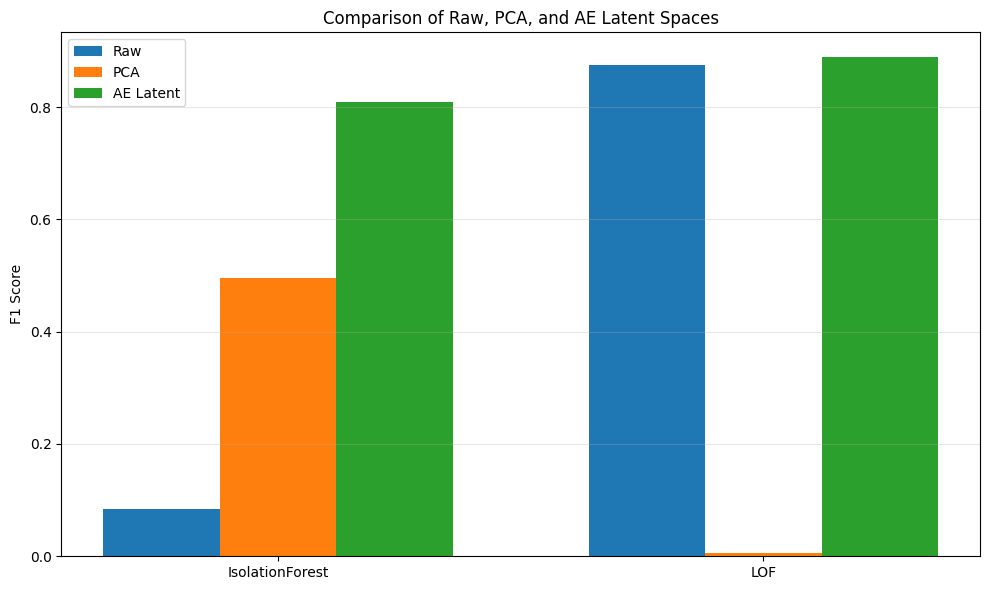

Saved: Figure_PCA_vs_AE_Comparison.png
Full path: /Users/emredelibas/Documents/Akademik/Python/ServetMakale/Figure_PCA_vs_AE_Comparison.png


In [10]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import os

# =========================
# EK CELL A) PCA vs AE KARŞILAŞTIRMASI
# Makaledeki yeri: Results -> Raw vs Latent comparison sonrası
# Export: 600 dpi PNG
# =========================

# --- PCA transform ---
pca = PCA(n_components=21, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca  = pca.transform(X_test_scaled)

# İstersen PCA space'i de standardize edebilirsin; burada karşılaştırma için bırakıyoruz
# ama daha stabil olsun istersen:
pca_scaler = StandardScaler()
X_train_pca = pca_scaler.fit_transform(X_train_pca)
X_test_pca  = pca_scaler.transform(X_test_pca)

# --- Sadece iki model: IF ve LOF ---
pca_rows = []

# Raw - IF
y_pred_raw_if, score_raw_if = if_predict(
    X_train_scaled, X_test_scaled,
    BEST_XSCALED["if_estimators"], BEST_XSCALED["if_contamination"]
)
m = metric_pack(y_test, y_pred_raw_if, score_raw_if)
pca_rows.append(["Raw", "IsolationForest", *m.values()])

# PCA - IF
y_pred_pca_if, score_pca_if = if_predict(
    X_train_pca, X_test_pca,
    BEST_XSCALED["if_estimators"], BEST_XSCALED["if_contamination"]
)
m = metric_pack(y_test, y_pred_pca_if, score_pca_if)
pca_rows.append(["PCA", "IsolationForest", *m.values()])

# AE - IF
y_pred_ae_if, score_ae_if = if_predict(
    z_train, z_test,
    BEST_ZLATENT["if_estimators"], BEST_ZLATENT["if_contamination"]
)
m = metric_pack(y_test, y_pred_ae_if, score_ae_if)
pca_rows.append(["AE Latent", "IsolationForest", *m.values()])

# Raw - LOF
y_pred_raw_lof, score_raw_lof = lof_predict(
    X_train_scaled, X_test_scaled,
    BEST_XSCALED["lof_neighbors"]
)
m = metric_pack(y_test, y_pred_raw_lof, score_raw_lof)
pca_rows.append(["Raw", "LOF", *m.values()])

# PCA - LOF
y_pred_pca_lof, score_pca_lof = lof_predict(
    X_train_pca, X_test_pca,
    BEST_XSCALED["lof_neighbors"]
)
m = metric_pack(y_test, y_pred_pca_lof, score_pca_lof)
pca_rows.append(["PCA", "LOF", *m.values()])

# AE - LOF
y_pred_ae_lof, score_ae_lof = lof_predict(
    z_train, z_test,
    BEST_ZLATENT["lof_neighbors"]
)
m = metric_pack(y_test, y_pred_ae_lof, score_ae_lof)
pca_rows.append(["AE Latent", "LOF", *m.values()])

df_pca_ae = pd.DataFrame(
    pca_rows,
    columns=["Space", "Model", "Precision", "Recall", "F1", "Macro-F1", "ROC-AUC"]
)

print("===== PCA vs AE KARŞILAŞTIRMASI =====")
display(df_pca_ae)

# --- Görsel: F1 karşılaştırması ---
plot_df = df_pca_ae[["Space", "Model", "F1"]].copy()

plt.figure(figsize=(10, 6))

models = plot_df["Model"].unique()
spaces = ["Raw", "PCA", "AE Latent"]
x = np.arange(len(models))
width = 0.24

for i, sp in enumerate(spaces):
    vals = []
    for m in models:
        vals.append(plot_df[(plot_df["Space"] == sp) & (plot_df["Model"] == m)]["F1"].values[0])
    plt.bar(x + (i-1)*width, vals, width=width, label=sp)

plt.xticks(x, models)
plt.ylabel("F1 Score")
plt.title("Comparison of Raw, PCA, and AE Latent Spaces")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

pca_fig_path = "Figure_PCA_vs_AE_Comparison.png"
plt.savefig(pca_fig_path, dpi=600, bbox_inches="tight")
plt.show()

print(f"Saved: {pca_fig_path}")
print("Full path:", os.path.abspath(pca_fig_path))

In [11]:
from sklearn.preprocessing import MinMaxScaler

# =========================
# 9) SCORE NORMALIZATION
# =========================

def normalize_scores(score_array):
    score_array = np.asarray(score_array).reshape(-1, 1)
    scaler = MinMaxScaler()
    return scaler.fit_transform(score_array).ravel()

# ROC plot için skor üret
roc_info_scaled = []
roc_info_latent = []

# Raw - DBSCAN
pred_db_raw, score_db_raw = dbscan_predict_like_train_test(
    X_train_scaled, X_test_scaled,
    BEST_XSCALED["dbscan_eps"], BEST_XSCALED["dbscan_min_samples"]
)
roc_info_scaled.append(("DBSCAN", normalize_scores(score_db_raw)))

# Raw - IF
_, score_if_raw = if_predict(
    X_train_scaled, X_test_scaled,
    BEST_XSCALED["if_estimators"], BEST_XSCALED["if_contamination"]
)
roc_info_scaled.append(("IF", normalize_scores(score_if_raw)))

# Raw - LOF
_, score_lof_raw = lof_predict(X_train_scaled, X_test_scaled, BEST_XSCALED["lof_neighbors"])
roc_info_scaled.append(("LOF", normalize_scores(score_lof_raw)))

# Raw - OCSVM
_, score_oc_raw = ocsvm_predict(
    X_train_scaled, X_test_scaled,
    BEST_XSCALED["ocsvm_nu"], BEST_XSCALED["ocsvm_gamma"]
)
roc_info_scaled.append(("OCSVM", normalize_scores(score_oc_raw)))

# Raw - kNN
_, score_knn_raw, _ = knn_predict(
    X_train_scaled, X_test_scaled,
    BEST_XSCALED["knn_k"], BEST_XSCALED["knn_percentile"]
)
roc_info_scaled.append(("kNN", normalize_scores(score_knn_raw)))

# Latent - DBSCAN
pred_db_lat, score_db_lat = dbscan_predict_like_train_test(
    z_train, z_test,
    BEST_ZLATENT["dbscan_eps"], BEST_ZLATENT["dbscan_min_samples"]
)
roc_info_latent.append(("DBSCAN", normalize_scores(score_db_lat)))

# Latent - IF
_, score_if_lat = if_predict(
    z_train, z_test,
    BEST_ZLATENT["if_estimators"], BEST_ZLATENT["if_contamination"]
)
roc_info_latent.append(("IF", normalize_scores(score_if_lat)))

# Latent - LOF
_, score_lof_lat = lof_predict(z_train, z_test, BEST_ZLATENT["lof_neighbors"])
roc_info_latent.append(("LOF", normalize_scores(score_lof_lat)))

# Latent - OCSVM
_, score_oc_lat = ocsvm_predict(
    z_train, z_test,
    BEST_ZLATENT["ocsvm_nu"], BEST_ZLATENT["ocsvm_gamma"]
)
roc_info_latent.append(("OCSVM", normalize_scores(score_oc_lat)))

# Latent - kNN
_, score_knn_lat, _ = knn_predict(
    z_train, z_test,
    BEST_ZLATENT["knn_k"], BEST_ZLATENT["knn_percentile"]
)
roc_info_latent.append(("kNN", normalize_scores(score_knn_lat)))

# Latent - AE Error
roc_info_latent.append(("AE Error", normalize_scores(re_test)))

print("ROC scores prepared.")

ROC scores prepared.


===== DEFAULT MODEL SONUÇLARI =====


,Space,Model,Precision,Recall,F1,Macro-F1,ROC-AUC
6,Latent,IsolationForest,0.848297,0.808260,0.827795,0.911665,0.990425
7,Latent,OCSVM,0.324468,0.179941,0.231499,0.607859,0.904000
8,Latent,kNN,0.216814,0.144543,0.173451,0.577614,0.819729
9,Latent,DBSCAN,0.025886,1.000000,0.050465,0.025233,0.500000
5,Latent,LOF,0.400000,0.005900,0.011628,0.499237,0.538571
3,Raw,kNN,0.287611,0.191740,0.230088,0.606557,0.880172
2,Raw,OCSVM,0.312500,0.147493,0.200401,0.592436,0.896171
1,Raw,IsolationForest,0.920000,0.067847,0.126374,0.557031,0.982257
4,Raw,DBSCAN,0.025886,1.000000,0.050465,0.025233,0.500000
0,Raw,LOF,0.000000,0.000000,0.000000,0.493326,0.549230


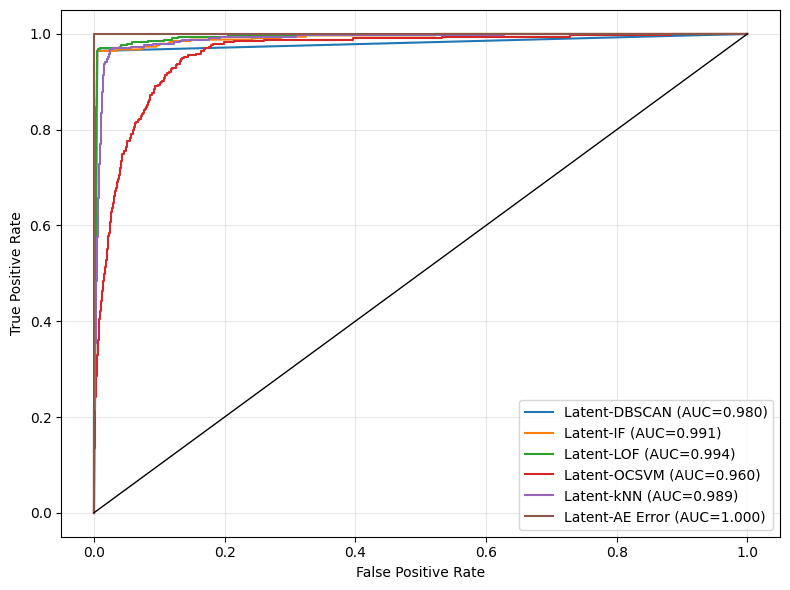

Saved: Figure_ROC_Comparison.png
Full path: /Users/emredelibas/Documents/Akademik/Python/ServetMakale/Figure_ROC_Comparison.png


In [12]:
# =========================
# 10) DEFAULT MODEL SONUÇLARI
# =========================

cont = float(max(y_train.mean(), 0.01))

def run_default_suite(space_name, Xtr, Xte, y_true):
    rows = []

    # LOF
    lof = LocalOutlierFactor(novelty=True)
    lof.fit(Xtr)
    pred = lof.predict(Xte)
    y_pred = (pred == -1).astype(int)
    scores = -lof.decision_function(Xte)
    m = metric_pack(y_true, y_pred, scores)
    rows.append([space_name, "LOF", *m.values()])

    # IF
    ifor = IsolationForest(random_state=42, contamination=cont)
    ifor.fit(Xtr)
    pred = ifor.predict(Xte)
    y_pred = (pred == -1).astype(int)
    scores = -ifor.decision_function(Xte)
    m = metric_pack(y_true, y_pred, scores)
    rows.append([space_name, "IsolationForest", *m.values()])

    # OCSVM
    oc = OneClassSVM(nu=cont)
    oc.fit(Xtr)
    pred = oc.predict(Xte)
    y_pred = (pred == -1).astype(int)
    scores = -oc.decision_function(Xte)
    m = metric_pack(y_true, y_pred, scores)
    rows.append([space_name, "OCSVM", *m.values()])

    # kNN
    nn = NearestNeighbors(n_neighbors=5)
    nn.fit(Xtr)
    dists, _ = nn.kneighbors(Xte)
    scores = dists.mean(axis=1)
    thr = np.quantile(scores, 1 - cont)
    y_pred = (scores >= thr).astype(int)
    m = metric_pack(y_true, y_pred, scores)
    rows.append([space_name, "kNN", *m.values()])

    # DBSCAN
    db = DBSCAN()
    labels = db.fit_predict(Xte)
    y_pred = (labels == -1).astype(int)
    m = metric_pack(y_true, y_pred, y_pred)
    rows.append([space_name, "DBSCAN", *m.values()])

    return rows

default_rows = []
default_rows += run_default_suite("Raw", X_train_scaled, X_test_scaled, y_test)
default_rows += run_default_suite("Latent", z_train, z_test, y_test)

df_default = pd.DataFrame(
    default_rows,
    columns=["Space", "Model", "Precision", "Recall", "F1", "Macro-F1", "ROC-AUC"]
).sort_values(["Space", "F1"], ascending=[True, False])

print("===== DEFAULT MODEL SONUÇLARI =====")
display(df_default)

from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import os

# =========================
# ROC CURVE PLOT
# =========================

plt.figure(figsize=(8, 6))

# LATENT SPACE
for name, scores in roc_info_latent:
    fpr, tpr, _ = roc_curve(y_test, scores)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, linestyle='-', label=f"Latent-{name} (AUC={roc_auc:.3f})")

# Diagonal
plt.plot([0, 1], [0, 1], 'k-', linewidth=1)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# 🔥 EXPORT
roc_path = "Figure_ROC_Comparison.png"
plt.savefig(roc_path, dpi=600, bbox_inches="tight")

plt.show()

print(f"Saved: {roc_path}")
print("Full path:", os.path.abspath(roc_path))

===== 10-FOLD CV ÖZET =====


,Space,Model,Precision_mean,Precision_std,Recall_mean,Recall_std,F1_mean,F1_std,MacroF1_mean,MacroF1_std,ROCAUC_mean,ROCAUC_std
5,Latent,DBSCAN,0.827366,0.068241,0.952302,0.045885,0.883989,0.049383,0.940883,0.025207,0.974351,0.023130
7,Latent,LOF,0.780473,0.067510,0.952302,0.045885,0.856298,0.048875,0.926728,0.024970,0.994296,0.005582
6,Latent,IsolationForest,0.780067,0.072535,0.778571,0.080379,0.776930,0.063279,0.886504,0.032175,0.985632,0.012487
9,Latent,kNN,0.344501,0.041112,0.606429,0.102689,0.438297,0.055331,0.712308,0.028225,0.973214,0.008780
8,Latent,OCSVM,0.328560,0.042529,0.328651,0.058204,0.327557,0.047979,0.657884,0.024250,0.949062,0.013934
2,Raw,LOF,0.809475,0.068837,0.946746,0.053423,0.870845,0.050208,0.934175,0.025642,0.994506,0.005600
0,Raw,DBSCAN,0.621151,0.068710,0.952302,0.045885,0.750157,0.057652,0.872240,0.029632,0.970923,0.023337
4,Raw,kNN,0.315514,0.027936,0.559048,0.073578,0.402825,0.039812,0.694113,0.020232,0.970660,0.007408
3,Raw,OCSVM,0.288713,0.072880,0.289762,0.080985,0.287985,0.075254,0.637741,0.038185,0.931570,0.027385
1,Raw,IsolationForest,0.049573,0.034910,0.050714,0.039787,0.049942,0.036925,0.516635,0.018642,0.933658,0.013342


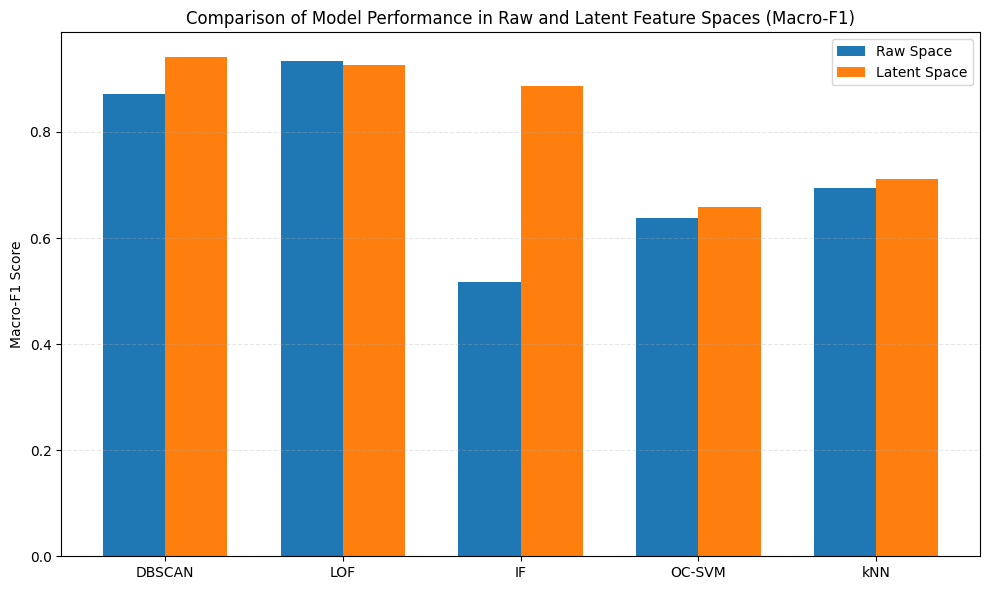

Saved: Figure_4_MacroF1_Comparison.png
Full path: /Users/emredelibas/Documents/Akademik/Python/ServetMakale/Figure_4_MacroF1_Comparison.png


In [13]:
from sklearn.model_selection import StratifiedKFold

# =========================
# 11) 10-FOLD CROSS-VALIDATION
# =========================

RANDOM_STATE = 42
N_SPLITS = 10

def cv_optimized(X, y, space_name, params):
    X = np.asarray(X)
    y = np.asarray(y).astype(int)

    skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
    fold_rows = []

    for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y), start=1):
        Xtr, Xva = X[tr_idx], X[va_idx]
        ytr, yva = y[tr_idx], y[va_idx]

        # IF
        y_pred, scores = if_predict(Xtr, Xva, params["if_estimators"], params["if_contamination"])
        m = metric_pack(yva, y_pred, scores)
        fold_rows.append([space_name, fold, "IsolationForest", *m.values()])

        # OCSVM
        y_pred, scores = ocsvm_predict(Xtr, Xva, params["ocsvm_nu"], params["ocsvm_gamma"])
        m = metric_pack(yva, y_pred, scores)
        fold_rows.append([space_name, fold, "OCSVM", *m.values()])

        # LOF
        y_pred, scores = lof_predict(Xtr, Xva, params["lof_neighbors"])
        m = metric_pack(yva, y_pred, scores)
        fold_rows.append([space_name, fold, "LOF", *m.values()])

        # kNN
        y_pred, scores, _ = knn_predict(Xtr, Xva, params["knn_k"], params["knn_percentile"])
        m = metric_pack(yva, y_pred, scores)
        fold_rows.append([space_name, fold, "kNN", *m.values()])

        # DBSCAN
        y_pred, scores = dbscan_predict_like_train_test(Xtr, Xva, params["dbscan_eps"], params["dbscan_min_samples"])
        m = metric_pack(yva, y_pred, scores)
        fold_rows.append([space_name, fold, "DBSCAN", *m.values()])

    df_folds = pd.DataFrame(
        fold_rows,
        columns=["Space", "Fold", "Model", "Precision", "Recall", "F1", "Macro-F1", "ROC-AUC"]
    )

    df_summary = df_folds.groupby(["Space", "Model"]).agg(
        Precision_mean=("Precision", "mean"),
        Precision_std=("Precision", "std"),
        Recall_mean=("Recall", "mean"),
        Recall_std=("Recall", "std"),
        F1_mean=("F1", "mean"),
        F1_std=("F1", "std"),
        MacroF1_mean=("Macro-F1", "mean"),
        MacroF1_std=("Macro-F1", "std"),
        ROCAUC_mean=("ROC-AUC", "mean"),
        ROCAUC_std=("ROC-AUC", "std")
    ).reset_index()

    return df_folds, df_summary

df_folds_x, df_sum_x = cv_optimized(X_train_scaled, y_train, "Raw", BEST_XSCALED)
df_folds_z, df_sum_z = cv_optimized(z_train, y_train, "Latent", BEST_ZLATENT)

df_cv_summary = pd.concat([df_sum_x, df_sum_z], ignore_index=True).sort_values(["Space", "F1_mean"], ascending=[True, False])

print("===== 10-FOLD CV ÖZET =====")
display(df_cv_summary)

import matplotlib.pyplot as plt
import numpy as np
import os

# =========================
# FIGURE 4 - MACRO-F1 COMPARISON
# =========================

# Model sırası (makale ile uyumlu)
models_order = ["DBSCAN", "LOF", "IsolationForest", "OCSVM", "kNN"]

# İsimleri makale formatına çevir
name_map = {
    "IsolationForest": "IF",
    "OCSVM": "OC-SVM",
    "kNN": "kNN",
    "LOF": "LOF",
    "DBSCAN": "DBSCAN"
}

# Raw ve Latent Macro-F1 çek
raw_df = df_cv_summary[df_cv_summary["Space"] == "Raw"].copy()
latent_df = df_cv_summary[df_cv_summary["Space"] == "Latent"].copy()

# sırala
raw_df = raw_df.set_index("Model").loc[models_order].reset_index()
latent_df = latent_df.set_index("Model").loc[models_order].reset_index()

# değerler
raw_scores = raw_df["MacroF1_mean"].values
latent_scores = latent_df["MacroF1_mean"].values

# x ekseni
x = np.arange(len(models_order))
width = 0.35

plt.figure(figsize=(10, 6))

# barlar
plt.bar(x - width/2, raw_scores, width, label="Raw Space")
plt.bar(x + width/2, latent_scores, width, label="Latent Space")

# etiketler
labels = [name_map[m] for m in models_order]
plt.xticks(x, labels)

plt.ylabel("Macro-F1 Score")
plt.title("Comparison of Model Performance in Raw and Latent Feature Spaces (Macro-F1)")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()

# 🔥 EXPORT
fig_path = "Figure_4_MacroF1_Comparison.png"
plt.savefig(fig_path, dpi=600, bbox_inches="tight")

plt.show()

print(f"Saved: {fig_path}")
print("Full path:", os.path.abspath(fig_path))

In [14]:
# =========================
# 12) HYPERPARAMETER OPTIMIZATION TABLOLARI
# =========================

# Default ve optimized sonuçları aynı formatta toparla
df_opt_for_table = df_compare.copy()
df_opt_for_table["Setting"] = "Optimized"

df_default_for_table = df_default.copy()
df_default_for_table["Setting"] = "Default"

df_hpo_compare = pd.concat([df_default_for_table, df_opt_for_table], ignore_index=True)

print("===== DEFAULT vs OPTIMIZED =====")
display(df_hpo_compare.sort_values(["Space", "Model", "Setting"]))

===== DEFAULT vs OPTIMIZED =====


,Space,Model,Precision,Recall,F1,Macro-F1,ROC-AUC,Setting
3,Latent,DBSCAN,0.025886,1.000000,0.050465,0.025233,0.500000,Default
15,Latent,DBSCAN,0.834184,0.964602,0.894665,0.945820,0.979753,Optimized
0,Latent,IsolationForest,0.848297,0.808260,0.827795,0.911665,0.990425,Default
16,Latent,IsolationForest,0.852941,0.769912,0.809302,0.902244,0.991383,Optimized
4,Latent,LOF,0.400000,0.005900,0.011628,0.499237,0.538571,Default
17,Latent,LOF,0.823678,0.964602,0.888587,0.942683,0.993816,Optimized
1,Latent,OCSVM,0.324468,0.179941,0.231499,0.607859,0.904000,Default
18,Latent,OCSVM,0.585366,0.353982,0.441176,0.714662,0.959624,Optimized
2,Latent,kNN,0.216814,0.144543,0.173451,0.577614,0.819729,Default
19,Latent,"kNN (k=300, p97)",0.763158,0.513274,0.613757,0.802605,0.988978,Optimized


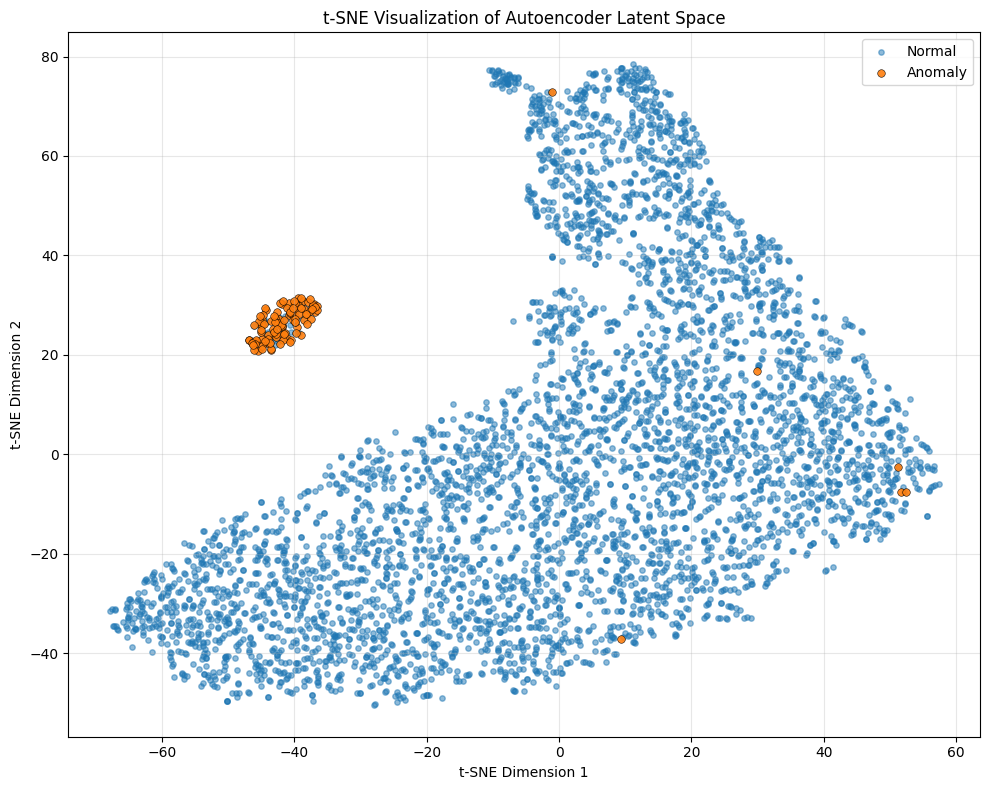

Saved: Figure_tSNE_Latent_Space.png
Full path: /Users/emredelibas/Documents/Akademik/Python/ServetMakale/Figure_tSNE_Latent_Space.png


In [15]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import os

# =========================
# 13) t-SNE LATENT SPACE
# =========================

z_all = np.vstack([z_train, z_test])
y_all = np.concatenate([y_train, y_test])

max_points = 5000
if z_all.shape[0] > max_points:
    np.random.seed(42)
    idx_sample = np.random.choice(z_all.shape[0], size=max_points, replace=False)
    z_tsne_input, y_tsne_input = z_all[idx_sample], y_all[idx_sample]
else:
    z_tsne_input, y_tsne_input = z_all, y_all

tsne = TSNE(n_components=2, random_state=42, init="random", learning_rate="auto")
z_tsne_2d = tsne.fit_transform(z_tsne_input)

plt.figure(figsize=(10, 8))

normal_idx = (y_tsne_input == 0)
anom_idx   = (y_tsne_input == 1)

plt.scatter(
    z_tsne_2d[normal_idx, 0],
    z_tsne_2d[normal_idx, 1],
    s=15, alpha=0.5, label="Normal"
)

plt.scatter(
    z_tsne_2d[anom_idx, 0],
    z_tsne_2d[anom_idx, 1],
    s=30, alpha=0.9, label="Anomaly",
    edgecolors="black", linewidth=0.4
)

plt.title("t-SNE Visualization of Autoencoder Latent Space")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# 🔥 EXPORT (EKLENEN KISIM)
tsne_path = "Figure_tSNE_Latent_Space.png"
plt.savefig(tsne_path, dpi=600, bbox_inches="tight")

plt.show()

print(f"Saved: {tsne_path}")
print("Full path:", os.path.abspath(tsne_path))

In [16]:
import shap
import matplotlib.pyplot as plt
import os
from xgboost import XGBClassifier

# =========================
# 14) SHAP / XAI (FIXED)
# =========================

# Model
clf = XGBClassifier(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.1,
    random_state=42,
    eval_metric="logloss"
)

clf.fit(z_train, y_train)

# 🔥 EXPLAINER (EN STABİL YÖNTEM)
explainer = shap.Explainer(clf, z_train)

# Background sample (çok büyük dataset için şart)
background = shap.sample(z_train, 1000, random_state=42) if z_train.shape[0] > 1000 else z_train

# SHAP değerleri
shap_values = explainer(background)

feature_names = [f"Latent Feature {i+1}" for i in range(z_train.shape[1])]

# =========================
# SUMMARY PLOT (GARANTİLİ)
# =========================
plt.figure()
shap.summary_plot(
    shap_values,
    background,
    feature_names=feature_names,
    show=False
)

summary_path = "Figure_SHAP_Summary.png"
plt.savefig(summary_path, dpi=600, bbox_inches="tight")
plt.close()

print(f"Saved: {summary_path}")
print("Full path:", os.path.abspath(summary_path))


# =========================
# WATERFALL (TEK ÖRNEK)
# =========================

# En anomaliye yakın örnek
proba_test = clf.predict_proba(z_test)[:, 1]
anom_idx = np.argmax(proba_test)

x_explain = z_test[anom_idx:anom_idx+1]

shap_values_single = explainer(x_explain)

plt.figure()
shap.waterfall_plot(shap_values_single[0], show=False)

waterfall_path = "Figure_SHAP_Waterfall.png"
plt.savefig(waterfall_path, dpi=600, bbox_inches="tight")
plt.close()

print(f"Saved: {waterfall_path}")
print("Full path:", os.path.abspath(waterfall_path))

print("Explained sample index:", anom_idx)

/Users/emredelibas/tf_env/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/var/folders/_h/6kzyggz563bc00q0_475j_lm0000gn/T/ipykernel_20561/1130552772.py:36: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


Saved: Figure_SHAP_Summary.png
Full path: /Users/emredelibas/Documents/Akademik/Python/ServetMakale/Figure_SHAP_Summary.png
Saved: Figure_SHAP_Waterfall.png
Full path: /Users/emredelibas/Documents/Akademik/Python/ServetMakale/Figure_SHAP_Waterfall.png
Explained sample index: 13052


In [17]:
from scipy.stats import wilcoxon

# =========================
# 15) WILCOXON TEST
# =========================

def run_global_wilcoxon(df_x, df_z, metric):
    dx = df_x[["Fold", "Model", metric]].copy()
    dz = df_z[["Fold", "Model", metric]].copy()

    dx.rename(columns={metric: "x"}, inplace=True)
    dz.rename(columns={metric: "z"}, inplace=True)

    merged = dx.merge(dz, on=["Fold", "Model"]).dropna()

    # Her fold içinde model ortalamaları
    fold_mean = merged.groupby("Fold")[["x", "z"]].mean()

    x_vals = fold_mean["x"].values
    z_vals = fold_mean["z"].values

    stat, p = wilcoxon(x_vals, z_vals)

    return {
        "Metric": metric,
        "Raw_mean": round(np.mean(x_vals), 4),
        "Latent_mean": round(np.mean(z_vals), 4),
        "Wilcoxon_stat": stat,
        "p_value": p
    }

wilcoxon_results = []
for metric in ["F1", "Macro-F1", "ROC-AUC"]:
    wilcoxon_results.append(run_global_wilcoxon(df_folds_x, df_folds_z, metric))

wilcoxon_results = pd.DataFrame(wilcoxon_results)

print("===== GLOBAL WILCOXON SONUÇLARI =====")
display(wilcoxon_results)

===== GLOBAL WILCOXON SONUÇLARI =====


,Metric,Raw_mean,Latent_mean,Wilcoxon_stat,p_value
0,F1,0.4724,0.6566,0.0,0.001953
1,Macro-F1,0.7310,0.8249,0.0,0.001953
2,ROC-AUC,0.9603,0.9753,0.0,0.001953
